# Лабораторная работа 3


In [1]:
import re

import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

train_df = pd.read_csv("artifacts/train_clean.csv")
test_df = pd.read_csv("artifacts/test_clean.csv")

BUG_REGEX = re.compile(r"\b(?:bug|error|fail|crash|broken|exception|wrong|incorrect)\b")
FEAT_REGEX = re.compile(r"\b(?:feature|enhancement|request|support|improve|proposal)\b")
TOKEN_REGEX = re.compile(r"[a-z][a-z0-9_]+")
STOP_WORDS = set(ENGLISH_STOP_WORDS)
RANDOM_STATE = 42

# Подготовка текста и разметка классов

In [2]:
def assign_label(title_col) -> str:
    text = "" if pd.isna(title_col) else str(title_col).lower()
    is_bug = BUG_REGEX.search(text) is not None
    is_feature = FEAT_REGEX.search(text) is not None
    if is_bug and is_feature:
        return "both"
    if is_bug:
        return "bug"
    if is_feature:
        return "feature"
    return "none"


def preprocess(text) -> list[str]:
    if not isinstance(text, str):
        text = ""
    text = text.lower().replace("</s>", " ").replace("<s>", " ")
    return " ".join([token for token in TOKEN_REGEX.findall(text) if token not in STOP_WORDS])


In [3]:
train_df["label"] = train_df["issue_title"].map(assign_label)
test_df["label"] = test_df["issue_title"].map(assign_label)

In [4]:
print("TRAIN: \n", train_df["label"].value_counts())
print("\nTEST: \n", test_df["label"].value_counts())

TRAIN: 
 label
none       138192
bug         13227
feature      8367
both          214
Name: count, dtype: int64

TEST: 
 label
none       34541
bug         3266
feature     2143
both          50
Name: count, dtype: int64


In [5]:
train_labeled = train_df[train_df["label"].isin(["bug", "feature"])].reset_index(drop=True)
test_labeled = test_df[test_df["label"].isin(["bug", "feature"])].reset_index(drop=True)
train_labeled["body_clean"] = train_labeled["body_clean"].apply(preprocess)
test_labeled["body_clean"] = test_labeled["body_clean"].apply(preprocess)
y_train = train_labeled["label"].to_numpy()
y_test = test_labeled["label"].to_numpy()

## 1. Bag of Words и TF-IDF


In [6]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

count_vectorizer = CountVectorizer(min_df=5, max_df=0.9)
tfidf_vectorizer = TfidfVectorizer(min_df=5, max_df=0.9)

X_train_bow = count_vectorizer.fit_transform(train_labeled["body_clean"])
X_test_bow = count_vectorizer.transform(test_labeled["body_clean"])
X_train_tfidf = tfidf_vectorizer.fit_transform(train_labeled["body_clean"])
X_test_tfidf = tfidf_vectorizer.transform(test_labeled["body_clean"])

bow_names = count_vectorizer.get_feature_names_out()
tfidf_names = tfidf_vectorizer.get_feature_names_out()


In [7]:
print(f"{X_train_bow.shape=}, test {X_test_bow.shape}")
print(f"{X_train_tfidf.shape=}, test {X_test_tfidf.shape=}")
print(f"{all(bow_names == tfidf_names)=}")

X_train_bow.shape=(21594, 9106), test (5409, 9106)
X_train_tfidf.shape=(21594, 9106), test X_test_tfidf.shape=(5409, 9106)
all(bow_names == tfidf_names)=True


In [8]:
print(bow_names[:20])

['a0' 'a1' 'a2' 'a3' 'aa' 'aaa' 'aaaa' 'aac' 'ab' 'abandoned' 'abc'
 'abc_iview' 'abcd' 'abi' 'abilities' 'ability' 'abis' 'able' 'abort'
 'aborted']


In [9]:
print(X_train_bow[0].toarray().sum())
print(X_train_tfidf[0].toarray().sum())

20
4.082599075489318


## 2. Классификаторы

Оба алгоритма обучаются на TF-IDF train.


In [10]:
from IPython.display import display
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.naive_bayes import MultinomialNB


sample_weight = compute_sample_weight(class_weight="balanced", y=y_train)
for label in train_labeled["label"].unique():
    print(f"sample_weight[{label}] = {sample_weight[y_train == label][0]:.4f}")

sample_weight[feature] = 1.2904
sample_weight[bug] = 0.8163


In [11]:
from sklearn.model_selection import GridSearchCV

nb_param_grid = {
    "alpha": [0.01, 0.1, 1.0, 2.0, 5.0, 10.0, 20.0],
}
nb = GridSearchCV(MultinomialNB(), nb_param_grid, cv=5)
nb.fit(X_train_tfidf, y_train, sample_weight=sample_weight)

nb_best = nb.best_estimator_
print(f"{nb_best.get_params()=}")


logreg_param_grid = {
    "C": [0.1, 1.0, 2.0],
}
logreg = GridSearchCV(LogisticRegression(class_weight="balanced", l1_ratio=0, max_iter=1000, solver="lbfgs"), logreg_param_grid, cv=5)
logreg.fit(X_train_tfidf, y_train, sample_weight=sample_weight)
logreg_best = logreg.best_estimator_
print(f"{logreg_best.get_params()=}")


def get_score_predictions(y_true, y_pred) -> dict:
    return {
        "macro_precision": precision_score(y_true, y_pred, average="macro", labels=["bug", "feature"]),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=["bug", "feature"]),
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=["bug", "feature"]),
        "accuracy": accuracy_score(y_true, y_pred),
    }


nb_pred = nb_best.predict(X_test_tfidf)
logreg_pred = logreg_best.predict(X_test_tfidf)
metrics = pd.DataFrame(
    [
        get_score_predictions(y_test, nb_pred),
        get_score_predictions(y_test, logreg_pred),
    ],
    index=["MultinomialNB", "LogisticRegression"],
)

baseline_accuracy = float((y_test == "bug").mean())
print(f"baseline accuracy: {baseline_accuracy:.4f}")
display(metrics.round(4))


nb_best.get_params()={'alpha': 10.0, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}
logreg_best.get_params()={'C': 1.0, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
baseline accuracy: 0.6038


,macro_precision,macro_recall,macro_f1,accuracy
MultinomialNB,0.8274,0.8312,0.8291,0.8355
LogisticRegression,0.8440,0.8494,0.8463,0.8517


## 3. Почему accuracy не главная метрика

Accuracy - это доля документов. В размеченном test класс bug составляет около 60%, поэтому константный выбор "bug" уже получает accuracy около 0.60.

Macro Precision, Macro Recall и Macro F1 считают bug и feature с одинаковым весом


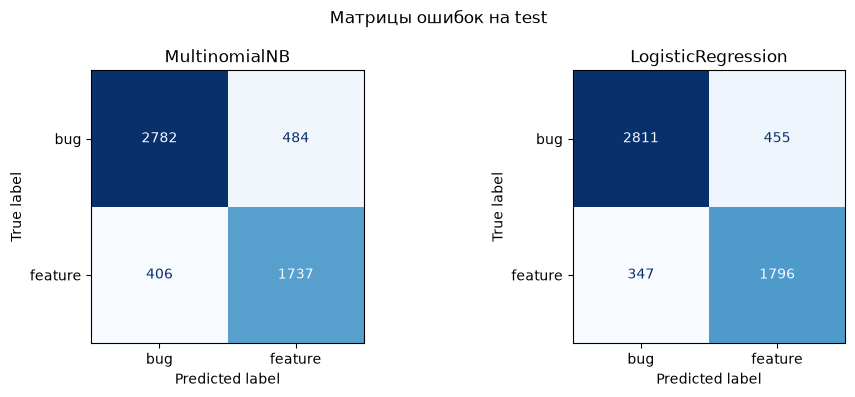

[[2811  455]
 [ 347 1796]]


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, pred in zip(axes, ["MultinomialNB", "LogisticRegression"], [nb_pred, logreg_pred]):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        labels=["bug", "feature"],
        ax=ax,
        colorbar=False,
        cmap="Blues",
    )
    ax.set_title(name)
fig.suptitle("Матрицы ошибок на test")
fig.tight_layout()
display(fig)
plt.close(fig)

print(confusion_matrix(y_test, logreg_pred, labels=["bug", "feature"]))


In [13]:
confidence = logreg.predict_proba(X_test_tfidf).max(axis=1)
error_mask = logreg_pred != y_test
error_frame = test_labeled.loc[error_mask].copy()
error_frame["prediction"] = logreg_pred[error_mask]
error_frame["confidence"] = confidence[error_mask]

top_mistakes = error_frame.sort_values(by="confidence", ascending=False).head(10)


for number, row in enumerate(top_mistakes.iterrows(), start=1):
    row = row[1]
    body = " ".join(str(row["body"]).split())
    print(f"\nПример {number}")
    print("Заголовок:", row["issue_title"])
    print("Истинная метка:", row["label"])
    print("Предсказание:", row["prediction"], f"(уверенность {row['confidence']:.3f})")
    print("Слов в body:", len(str(row["body"]).split()))
    print("Фрагмент body:", body[:400])



Пример 1
Заголовок: cura 3.1.0 - skirt bug
Истинная метка: bug
Предсказание: feature (уверенность 0.996)
Слов в body: 22
Фрагмент body: the skirt only surrounds support area while using supports. this creates unwanted filament under the model. without supports it functions as normal.

Пример 2
Заголовок: can't get encryption feature to work
Истинная метка: feature
Предсказание: bug (уверенность 0.989)
Слов в body: 101
Фрагмент body: i can encrypt an item, but the result is not usable. yes i've got the item name and key in keys.json . here's the error i get: error exception while calling script init: luaexception error code 2, string /itemscripts/weapon_plus.lua :356: bad argument 1 to 'for iterator' table expected, got nil and the full log: https://gist.github.com/manauser/1800dbfb42e3035fe8bbd8fd633a5d3e i demonstrated this 

Пример 3
Заголовок: feature request delete erroneous imported components
Истинная метка: feature
Предсказание: bug (уверенность 0.986)
Слов в body: 31
Фрагмент 

In [14]:
top_mistakes

,issue_title,body,body_clean,label,prediction,confidence
2243,cura 3.1.0 - skirt bug,the skirt only surrounds support area while us...,skirt surrounds support area using supports cr...,bug,feature,0.996297
4341,can't get encryption feature to work,"i can encrypt an item, but the result is not u...",encrypt item result usable yes ve got item key...,feature,bug,0.989355
431,feature request delete erroneous imported comp...,"when an important error has an error, there is...",important error error way delete component usi...,feature,bug,0.986284
606,xcode 8.3.2 no such module error,please update telegram bot to support xcode 8....,update telegram bot support xcode num num thanks,bug,feature,0.984132
217,request for assigned_to 'username' attribute i...,expected behavior or desired behavior if a fea...,expected behavior desired behavior feature req...,feature,bug,0.981965
1745,bug: need to be able to add timeout to helm test,<!-- thanks for filing an issue! before submit...,bug report feature request choose bug bug repo...,bug,feature,0.978539
3233,support branches are not supported,steps to reproduce: 1. git flow support start ...,steps reproduce num git flow support start num...,feature,bug,0.978356
3449,task improve instanciation of tsfe in initiali...,when we currently instanciate the tsfe in util...,currently instanciate tsfe util initializetsfe...,feature,bug,0.976650
4470,release_notes link in readme broken,release notes https://github.com/fable-compile...,release notes url like release notes split let...,bug,feature,0.968491
1545,bad alloc crash with circuit involved,see whether this is useful: https://github.com...,useful url,bug,feature,0.968151


## 4. Инвертированный индекс

Индекс строится по всему корпусу train и test, 200 000 документов, по `body_clean` без вырезания слов-меток. Номер - позиция в объединенном датасете: train `0…159999`, test `160000…199999`.


In [15]:
def tokenize(text) -> list[str]:
    return [token for token in TOKEN_REGEX.findall(text)]

In [16]:
from collections import Counter, defaultdict

corpus_titles = pd.concat(
    [train_df["issue_title"].fillna(""), test_df["issue_title"].fillna("")],
    ignore_index=True,
)
corpus_bodies = pd.concat(
    [train_df["body"].fillna(""), test_df["body"].fillna("")],
    ignore_index=True,
)
corpus_body_clean = pd.concat(
    [train_df["body_clean"].fillna(""), test_df["body_clean"].fillna("")],
    ignore_index=True,
)
tokenized_docs = [tokenize(text) for text in corpus_body_clean]

inverted_index = defaultdict(list)
term_freqs = defaultdict(list)
document_length = []
for doc_id, tokens in enumerate(tokenized_docs):
    document_length.append(len(tokens))
    for term, freq in Counter(tokens).items():
        inverted_index[term].append(doc_id)
        term_freqs[term].append(freq)
inverted_index = dict(inverted_index)
term_freqs = dict(term_freqs)

example_term = "exception"
print(f"Документов в корпусе: {len(document_length)}")
print(f"Терминов в индексе: {len(inverted_index)}")
print(f"Постинг «{example_term}»: {len(inverted_index[example_term])} документов")
print("Первые doc_id:", inverted_index[example_term][:8])
print("Частоты этих документов:", term_freqs[example_term][:8])
print("Списки doc_id отсортированы:", inverted_index[example_term] == sorted(inverted_index[example_term]))
print("Заголовки первых документов:")
for doc_id in inverted_index[example_term][:5]:
    print(f"  {doc_id}: {corpus_titles.iloc[doc_id]}")


Документов в корпусе: 200000
Терминов в индексе: 346658
Постинг «exception»: 3400 документов
Первые doc_id: [77, 143, 270, 317, 369, 393, 512, 591]
Частоты этих документов: [1, 3, 1, 1, 1, 1, 1, 1]
Списки doc_id отсортированы: True
Заголовки первых документов:
  77: terminal.eraseline gives overflowerror on windows
  143: typeerror: build_attrs takes from 1 to 2 positional arguments but 3 were given
  270: failure: build failed with an exception.
  317: cast text column to integer for the postgresql
  369: game crashes in-game while hosting and someone joins


## 5. Поиск Okapi BM25

$$
\mathrm{IDF}(q)=\ln\left(\frac{N-\mathrm{df}+0.5}{\mathrm{df}+0.5}+1\right)
$$

$$
\mathrm{score}(d,Q)=\sum_{q \in Q}\mathrm{IDF}(q)\cdot\frac{\mathrm{tf}(q,d)\,(k_1+1)}{\mathrm{tf}(q,d)+k_1\left(1-b+b\frac{|d|}{\mathrm{avgdl}}\right)}
$$

Параметры: $k_1=1.5$, $b=0.75$. Кандидаты берутся из инвертированного индекса.


In [17]:
import bisect
import math

def bm25_search(query, k=5, k1=1.5, b=0.75):
    terms = tokenize(query)
    n_docs = len(document_length)
    avgdl = sum(document_length) / n_docs
    unique_terms = list(dict.fromkeys(terms))
    posting_sets = [set(inverted_index[term]) for term in unique_terms if term in inverted_index]
    intersection = set.intersection(*posting_sets) if posting_sets else set()
    candidate_ids = set.union(*posting_sets) if posting_sets else set()

    scored = []
    for doc_id in candidate_ids:
        dl = document_length[doc_id]
        score = 0.0
        for term in terms:
            postings = inverted_index.get(term)
            if not postings:
                continue
            pos = bisect.bisect_left(postings, doc_id)
            if pos >= len(postings) or postings[pos] != doc_id:
                continue
            tf = term_freqs[term][pos]
            df = len(postings)
            idf = math.log((n_docs - df + 0.5) / (df + 0.5) + 1.0)
            denominator = tf + k1 * (1.0 - b + b * dl / avgdl)
            score += idf * tf * (k1 + 1.0) / denominator
        scored.append((score, doc_id))
    scored.sort(key=lambda item: (-item[0], item[1]))
    return terms, intersection, scored[:k]

queries = [
    "crash null pointer exception",
    "feature proposal configuration option",
    "how to install and configure",
]
for query in queries:
    terms, intersection, hits = bm25_search(query)
    print(f"\nЗапрос: {query}")
    print("Термы после токенизации:", terms)
    print("Документов в полном пересечении термов:", len(intersection))
    rows = []
    for rank, (score, doc_id) in enumerate(hits, start=1):
        snippet = " ".join(str(corpus_bodies.iloc[doc_id]).split())
        rows.append(
            {
                "rank": rank,
                "doc_id": doc_id,
                "score": round(score, 4),
                "issue_title": corpus_titles.iloc[doc_id],
                "snippet": snippet[:180],
            }
        )
    display(pd.DataFrame(rows))



Запрос: crash null pointer exception
Термы после токенизации: ['crash', 'null', 'pointer', 'exception']
Документов в полном пересечении термов: 1


,rank,doc_id,score,issue_title,snippet
0,1,103231,23.4564,exceptions from renameshortname,throws null pointer exception. i disabled it f...
1,2,157515,22.6278,isolated workspaces backwards compatibility issue,loading a data directory with isolated workspa...
2,3,133124,21.4679,cheetah digital sdk 1.2: app crashes when ems_...,"hi, i am using test push notifications website..."
3,4,45047,21.3695,sessionauthenticated hook failed because of a ...,the main sessionauthenticated hook failed with...
4,5,135960,21.3695,clear filters causes unhandled exception,when in state produced by 75 hitting clear fil...



Запрос: feature proposal configuration option
Термы после токенизации: ['feature', 'proposal', 'configuration', 'option']
Документов в полном пересечении термов: 2


,rank,doc_id,score,issue_title,snippet
0,1,9252,20.2148,add autocomplete= off to all configuration inputs,this is a feature proposal description add aut...
1,2,161499,16.3490,feature request: use cosmiconfig for configura...,<!-- please answer the following questions. is...
2,3,168590,15.0840,support identityvalidationexpression on author...,feature proposal description support identityv...
3,4,158213,14.3735,artifact plugins capabilities,issue type - feature proposal summary ask arti...
4,5,25706,14.0427,remove old gallery view,feature proposal the old gallery view can be r...



Запрос: how to install and configure
Термы после токенизации: ['how', 'to', 'install', 'and', 'configure']
Документов в полном пересечении термов: 28


,rank,doc_id,score,issue_title,snippet
0,1,107767,17.5039,update main readme,description/steps to reproduce enter the repo ...
1,2,188474,15.8650,build mlt with movit,hi i have download the lastest source of movit...
2,3,39684,15.3554,gocrack for kali linux,hi. who can help me to install and configure g...
3,4,3674,15.0213,create a build script,create a shell script to automatically install...
4,5,119690,14.8348,folly configure checking whether the boost::co...,i try build the folly. there have an error for...


## 6. LDA и coherence $C_V$

Словарь gensim строится по всем 200 000 документам: `no_below=10`, `no_above=0.5`, не больше 10 000 слов. Подбор числа тем и финальная модель считаются на случайной подвыборке 20 000 документов. Расчет coherence $C_V$ по полному корпусу слишком тяжелый, поэтому на графике расчеты для той же фиксированной подвыборки.

Сетка K: 2, 4, 6, 8, 10, 12, 15, 20. Модель: `passes=10`, `iterations=50`.


Слов в словаре LDA: 10000
Документов в подвыборке coherence: 20000
K=2: coherence c_v=0.4745
K=4: coherence c_v=0.4175
K=6: coherence c_v=0.4863
K=8: coherence c_v=0.5207
K=10: coherence c_v=0.5011
K=12: coherence c_v=0.5045
K=15: coherence c_v=0.4979
K=20: coherence c_v=0.4723
Максимум при K=8 (0.5207)
Выбранное K=8 (0.5207)


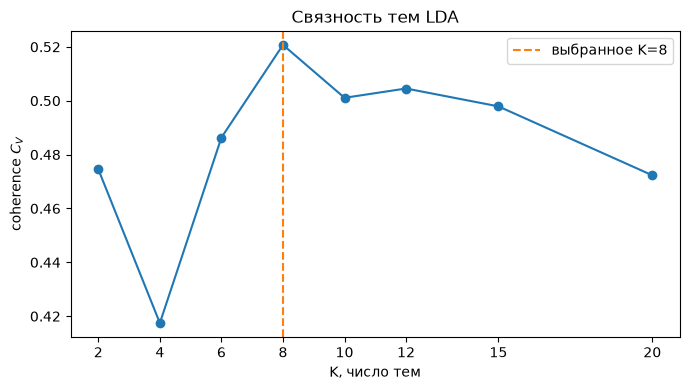


Топ-10 слов для K=8
Тема 0: you (0.033), url (0.028), this (0.022), and (0.020), on (0.017), for (0.015), of (0.015), your (0.015), we (0.013), in (0.011)
Тема 1: js (0.077), at (0.047), module (0.044), in (0.030), from (0.024), npm (0.021), src (0.019), node (0.019), first (0.016), node_modules (0.016)
Тема 2: nonlatin (0.446), de (0.028), url (0.016), la (0.012), en (0.010), que (0.009), el (0.008), un (0.006), se (0.006), le (0.006)
Тема 3: on (0.027), and (0.027), in (0.020), url (0.020), of (0.019), is (0.019), it (0.016), when (0.014), this (0.010), page (0.009)
Тема 4: num (0.424), in (0.015), version (0.013), file (0.011), line (0.009), url (0.009), lib (0.006), py (0.006), error (0.006), hex (0.006)
Тема 5: error (0.029), java (0.012), at (0.010), this (0.009), name (0.009), is (0.009), type (0.009), string (0.008), not (0.008), test (0.008)
Тема 6: is (0.028), it (0.026), and (0.025), in (0.022), be (0.021), of (0.020), this (0.019), that (0.019), for (0.019), with (0.011)
Т

In [18]:
import logging

from gensim.corpora import Dictionary
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel

logging.getLogger("gensim").setLevel(logging.ERROR)

dictionary = Dictionary(tokenized_docs)
dictionary.filter_extremes(no_below=10, no_above=0.5, keep_n=10000)
print(f"Слов в словаре LDA: {len(dictionary)}")

sample_rng = np.random.default_rng(RANDOM_STATE)
sample_idx = np.sort(sample_rng.choice(len(tokenized_docs), size=20000, replace=False))
sample_tokens = [tokenized_docs[i] for i in sample_idx]
sample_corpus = [dictionary.doc2bow(tokens) for tokens in sample_tokens]
print(f"Документов в подвыборке coherence: {len(sample_tokens)}")

k_grid = [2, 4, 6, 8, 10, 12, 15, 20]
coherence_by_k = {}
lda_models = {}
for k in k_grid:
    lda = LdaModel(
        corpus=sample_corpus,
        id2word=dictionary,
        num_topics=k,
        random_state=RANDOM_STATE,
        passes=10,
        iterations=50,
        eval_every=None,
        chunksize=2000,
    )
    coherence = CoherenceModel(
        model=lda,
        texts=sample_tokens,
        dictionary=dictionary,
        coherence="c_v",
        processes=1,
    ).get_coherence()
    coherence_by_k[k] = float(coherence)
    lda_models[k] = lda
    print(f"K={k}: coherence c_v={coherence:.4f}")

k_star = max(k_grid, key=coherence_by_k.get)
chosen_k = k_star
chosen_pos = k_grid.index(k_star)
while chosen_pos > 0 and coherence_by_k[k_star] - coherence_by_k[k_grid[chosen_pos - 1]] <= 0.01:
    chosen_pos -= 1
    chosen_k = k_grid[chosen_pos]
print(f"Максимум при K={k_star} ({coherence_by_k[k_star]:.4f})")
print(f"Выбранное K={chosen_k} ({coherence_by_k[chosen_k]:.4f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_grid, [coherence_by_k[k] for k in k_grid], marker="o")
ax.axvline(chosen_k, color="C1", linestyle="--", label=f"выбранное K={chosen_k}")
ax.set_xlabel("K, число тем")
ax.set_ylabel("coherence $C_V$")
ax.set_title("Связность тем LDA")
ax.set_xticks(k_grid)
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

final_lda = lda_models[chosen_k]
print(f"\nТоп-10 слов для K={chosen_k}")
for topic_id, words in final_lda.show_topics(num_topics=chosen_k, num_words=10, formatted=False):
    formatted = ", ".join(f"{word} ({weight:.3f})" for word, weight in words)
    print(f"Тема {topic_id}: {formatted}")


## 7. Интерпретация тем

Максимум coherence на сетке - K=8, $C_V = 0.5207$.

1. **Модули Node.js.**
1. **Потоки управления и роли.**
2. **Неанглийский текст.**
3. **Страница и ссылки.**
4. **Python.**
5. **Java.**
6. **Служебные слова.**
7. **Баг-репорт.**
